In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import timm  # Hugging Face's library for Vision Transformers
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from PIL import Image

c:\Users\Admin\projects\CNN\CNN\code\new\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 1. Load and Preprocess Data
df = pd.read_csv("fer2013.csv")

# Convert pixel strings to numpy arrays
df['pixels'] = df['pixels'].apply(lambda x: np.array(x.split(), dtype=np.float32).reshape(48, 48))

# Convert grayscale images to 3-channel images for ViT
def to_rgb(image):
    return np.stack([image] * 3, axis=-1)  # Convert (48,48) to (48,48,3)

df['pixels'] = df['pixels'].apply(to_rgb)

# Map emotions to stress levels
stress_mapping = {0: "low", 1: "low", 2: "neutral", 3: "neutral", 4: "high", 5: "high", 6: "high"}
df['emotion'] = df['emotion'].map(stress_mapping)

# Encode labels
label_encoder = LabelEncoder()
df['emotion'] = label_encoder.fit_transform(df['emotion'])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(df['pixels'].values, df['emotion'].values, test_size=0.2, random_state=42, stratify=df['emotion'])

# Convert images and labels to torch tensors
class FERDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx].astype(np.uint8)  # Convert float to uint8
        image = Image.fromarray(image)  # Convert to PIL image
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

# Define Image Transformations (Resizing for ViT)
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ViT requires 224x224 input size
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalize to [-1,1]
])

# Create PyTorch datasets
train_dataset = FERDataset(X_train, y_train, transform=transform)
test_dataset = FERDataset(X_test, y_test, transform=transform)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [3]:
import torch
import timm
import torch.nn as nn

# 2. Load Pretrained ViT Model and Modify for Stress Detection
class ViTStressDetector(nn.Module):
    def __init__(self, num_classes=3):
        super(ViTStressDetector, self).__init__()
        self.vit = timm.create_model("vit_base_patch16_224", pretrained=True)  # Load pre-trained ViT

        # Add a custom classification head with dropout and activation
        in_features = self.vit.head.in_features
        self.vit.head = nn.Sequential(
            nn.LayerNorm(in_features),  # Layer Normalization for stability
            nn.Dropout(0.3),  # Dropout to reduce overfitting
            nn.Linear(in_features, 512),  # Intermediate Layer
            nn.ReLU(),  # Activation Function
            nn.Dropout(0.2),  # More dropout
            nn.Linear(512, num_classes)  # Final output layer
        )

    def forward(self, x):
        return self.vit(x)

# Define device and check CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ViTStressDetector(num_classes=3).to(device)

# Print CUDA status
print("CUDA Available:", torch.cuda.is_available())
print("Using Device:", device)
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Device Count:", torch.cuda.device_count())


CUDA Available: True
Using Device: cuda
GPU Name: NVIDIA GeForce GTX 1650
CUDA Device Count: 1


In [4]:
import torch
print("CUDA Available:", torch.cuda.is_available())  
print("CUDA Version:", torch.version.cuda)  
print("Device Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")


CUDA Available: True
CUDA Version: 11.8
Device Name: NVIDIA GeForce GTX 1650


In [5]:
# 3. Train the Model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=3e-5)

num_epochs = 10  # You can increase this for better results

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct, total = 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_accuracy = correct / total
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss:.4f}, Accuracy: {train_accuracy:.4f}")

Epoch 1/10, Loss: 630.6808, Accuracy: 0.7016
Epoch 2/10, Loss: 501.6927, Accuracy: 0.7727
Epoch 3/10, Loss: 397.8658, Accuracy: 0.8254
Epoch 4/10, Loss: 286.2724, Accuracy: 0.8816
Epoch 5/10, Loss: 196.6308, Accuracy: 0.9207
Epoch 6/10, Loss: 137.4384, Accuracy: 0.9463
Epoch 7/10, Loss: 102.1070, Accuracy: 0.9611
Epoch 8/10, Loss: 81.8215, Accuracy: 0.9689
Epoch 9/10, Loss: 82.7087, Accuracy: 0.9683
Epoch 10/10, Loss: 57.4742, Accuracy: 0.9784


Test Accuracy: 0.7512

Classification Report:
              precision    recall  f1-score   support

        high       0.80      0.75      0.77      3256
         low       0.61      0.67      0.64      1100
     neutral       0.76      0.78      0.77      2822

    accuracy                           0.75      7178
   macro avg       0.72      0.74      0.73      7178
weighted avg       0.75      0.75      0.75      7178



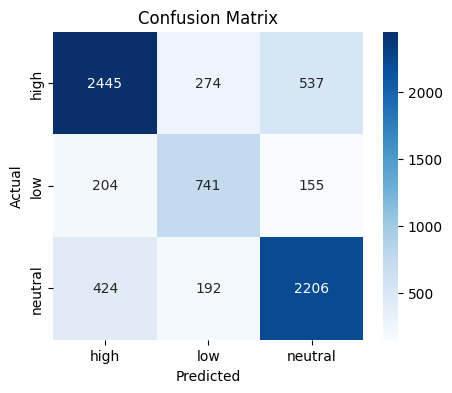

In [6]:
# 4. Evaluate Model on Test Data
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate Metrics
accuracy = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

# Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(all_labels, all_preds), annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()



In [7]:
# 5. Save Model and Label Encoder
torch.save(model.state_dict(), "stress_detection_vit.pth")
joblib.dump(label_encoder, "label_encoder.pkl")

print("\nModel saved successfully!")


Model saved successfully!
